# 04 — Treinamento da LSTM no walk-forward

Este notebook mostra como a LSTM foi treinada e o que ela conseguiu aprender. O
experimento completo roda em `scripts/run_walk_forward.py` (cerca de 80 s por janela);
aqui lemos o que ele registrou e refazemos uma janela para ver o treino de perto.

**Desenho.** Cada janela tem cinco anos de desenvolvimento, divididos em quatro blocos
cronológicos:

1. **treino**, onde a rede ajusta os pesos;
2. **validação**, usada só para a parada antecipada (paciência de 15 épocas);
3. **calibração** (252 pregões), que fornece os erros usados depois no VaR/ES;
4. **teste** (seis meses), avaliado uma única vez.

A seleção de variáveis (ausências e VIF), a padronização e o HMM (inclusive o número de
estados) são ajustados só no treino. A janela anda seis meses por vez.

**Arquitetura.** Duas camadas LSTM (64 e 32 unidades), dropout de 0,3, sequências de 42
pregões, Adam com taxa de 0,001, lotes de 32 e erro quadrático do log-retorno padronizado
da carteira no pregão seguinte. A HMM-LSTM recebe as mesmas entradas e, além delas, o
regime do filtro Forward em codificação one-hot. Os hiperparâmetros foram fixados antes do
experimento; não houve busca em grade.

In [1]:
import json
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

logging.getLogger("hmmlearn").setLevel(logging.ERROR)  # avisos de convergência do Baum-Welch
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.features import get_b3_trading_days
from src.data.risk_dataset import build_risk_split_dataset, make_risk_walk_forward_splits
from src.models.lstm import TrainingConfig, fit_lstm

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "reports" / "tables" / "walk_forward"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False})

config = yaml.safe_load((PROJECT_ROOT / "config.yaml").read_text(encoding="utf-8"))
features = pd.read_parquet(PROCESSED_DIR / "features.parquet")
portfolio = pd.read_parquet(PROCESSED_DIR / "portfolio_return.parquet")
sessions = get_b3_trading_days(features.index.min(), features.index.max())
features, portfolio = features.reindex(sessions), portfolio.reindex(sessions)
manifest = pd.DataFrame(json.loads((RESULTS_DIR / "manifest.json").read_text(encoding="utf-8")))

start = portfolio.dropna().index.min()
splits = make_risk_walk_forward_splits(sessions[sessions >= start], calibration_sessions=252)
print(f"{len(splits)} janelas; teste de {splits[0].test[0].date()} a {splits[-1].test[-1].date()}")

23 janelas; teste de 2012-09-28 a 2024-03-27


## As janelas

A tabela traz as datas de cada bloco e o número de sequências utilizáveis. Uma sequência só
entra quando os 42 pregões anteriores estão completos e o alvo cai no mesmo bloco, por isso
há menos sequências do que pregões.

In [2]:
hmm_rows = manifest[manifest.model == "hmm_lstm"].set_index("fold")
windows = pd.DataFrame({
    "treino": [f"{s.train[0]:%m/%Y}–{s.train[-1]:%m/%Y}" for s in splits],
    "calibração": [f"{s.calibration[0]:%m/%Y}–{s.calibration[-1]:%m/%Y}" for s in splits],
    "teste": [f"{s.test[0]:%d/%m/%Y}–{s.test[-1]:%d/%m/%Y}" for s in splits],
}, index=pd.Index(range(len(splits)), name="janela"))
for block in ("train", "validation", "calibration", "test"):
    windows[f"n_{block}"] = hmm_rows.n_sequences.map(lambda d: d[block])
windows["estados_hmm"] = hmm_rows.n_states
windows

,treino,calibração,teste,n_train,n_validation,n_calibration,n_test,estados_hmm
janela,,,,,,,,
0,09/2007–02/2011,09/2011–09/2012,28/09/2012–27/03/2013,676,147,251,117,4.0
1,03/2008–08/2011,03/2012–03/2013,28/03/2013–27/09/2013,717,147,251,127,4.0
2,09/2008–02/2012,09/2012–09/2013,30/09/2013–27/03/2014,757,147,251,120,4.0
3,03/2009–08/2012,03/2013–03/2014,28/03/2014–26/09/2014,709,147,251,86,3.0
4,09/2009–02/2013,09/2013–09/2014,29/09/2014–27/03/2015,835,147,212,56,4.0
5,03/2010–08/2013,03/2014–03/2015,30/03/2015–25/09/2015,840,147,145,123,4.0
6,09/2010–02/2014,09/2014–09/2015,28/09/2015–24/03/2016,838,113,180,118,4.0
7,03/2011–08/2014,03/2015–03/2016,28/03/2016–27/09/2016,831,47,251,128,4.0
8,09/2011–02/2015,09/2015–09/2016,28/09/2016–27/03/2017,731,147,251,121,4.0


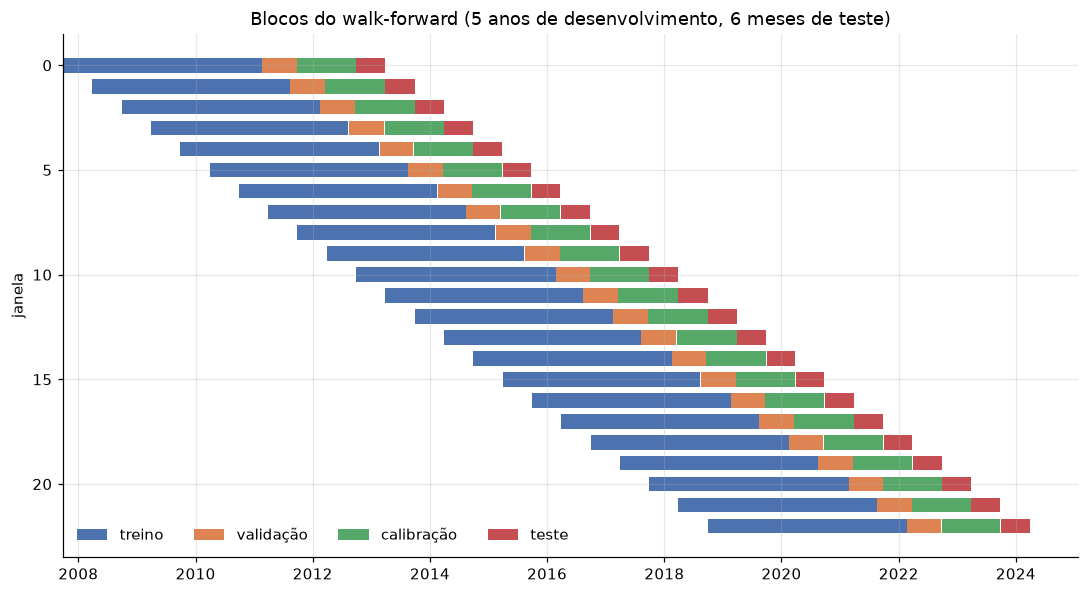

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = {"train": "#4C72B0", "validation": "#DD8452", "calibration": "#55A868", "test": "#C44E52"}
labels = {"train": "treino", "validation": "validação", "calibration": "calibração", "test": "teste"}
for i, s in enumerate(splits):
    for block, color in colors.items():
        dates = getattr(s, block)
        ax.barh(i, (dates[-1] - dates[0]).days, left=dates[0], color=color, height=.7,
                label=labels[block] if i == 0 else None)
ax.invert_yaxis()
ax.set_ylabel("janela")
ax.set_title("Blocos do walk-forward (5 anos de desenvolvimento, 6 meses de teste)")
ax.legend(loc="lower left", ncol=4, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_walk_forward_janelas.png", bbox_inches="tight")

## Uma janela de perto: teste de out/2019 a mar/2020

A janela 14 tem a queda da Covid no fim do teste, o que a torna uma boa ilustração. O
código repete exatamente a configuração do experimento. Como o treino é determinístico
(CPU, semente fixa), a melhor época tem de coincidir com a registrada no manifesto.

In [4]:
FOLD = 14
split = splits[FOLD]
data = build_risk_split_dataset(features, portfolio, split, sessions=sessions, lookback=42,
                                vif_threshold=config["features"]["vif_threshold"],
                                hmm_n_init=10, random_state=config["random_seed"])
training = TrainingConfig(hidden=tuple(config["lstm"]["layers"]), dropout=0.3, learning_rate=0.001,
                          batch_size=32, patience=config["lstm"]["early_stopping_patience"],
                          seed=config["random_seed"])
columns = data["columns"]
regime_cols = [i for i, c in enumerate(columns) if c[0] == "regime"]
plain_cols = [i for i, c in enumerate(columns) if c[0] != "regime"]
print(f"{len(plain_cols)} variáveis selecionadas no treino + {len(regime_cols)} colunas de regime "
      f"({data['n_states']} estados)")

histories = {}
for name, chosen in (("lstm", plain_cols), ("hmm_lstm", plain_cols + regime_cols)):
    model, info = fit_lstm(data["X_train"][:, :, chosen], data["y_train"],
                           data["X_validation"][:, :, chosen], data["y_validation"], config=training)
    histories[name] = pd.DataFrame(info["history"]).set_index("epoch")
    recorded = int(manifest.query("fold == @FOLD and model == @name").best_epoch.iloc[0])
    print(f"{name}: melhor época {info['best_epoch']} (manifesto: {recorded}), "
          f"parou na época {len(info['history'])}")
    assert info["best_epoch"] == recorded

83 variáveis selecionadas no treino + 4 colunas de regime (4 estados)


lstm: melhor época 1 (manifesto: 1), parou na época 16


hmm_lstm: melhor época 7 (manifesto: 7), parou na época 22


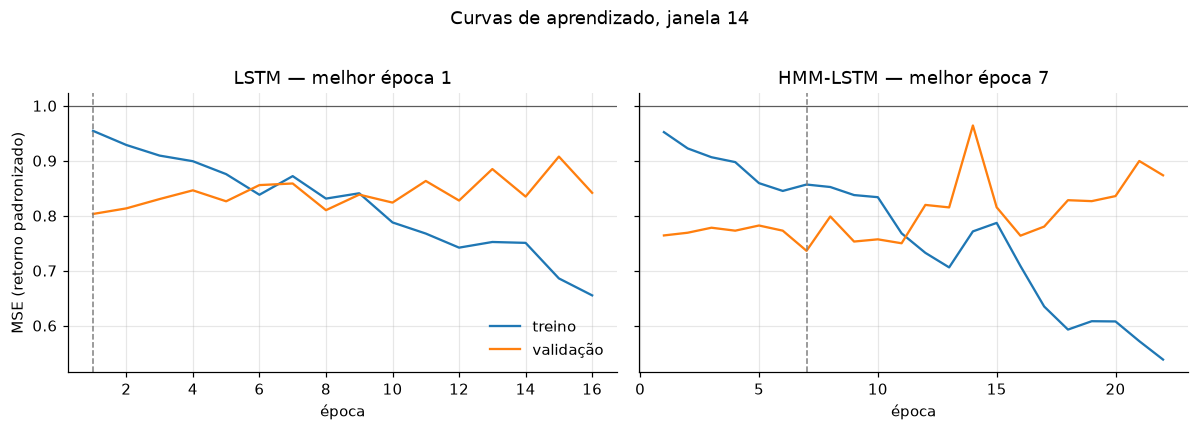

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, title) in zip(axes, (("lstm", "LSTM"), ("hmm_lstm", "HMM-LSTM"))):
    h = histories[name]
    ax.plot(h.index, h.train_mse, label="treino")
    ax.plot(h.index, h.validation_mse, label="validação")
    best = h.validation_mse.idxmin()
    ax.axvline(best, color="gray", ls="--", lw=1)
    ax.axhline(1, color="black", lw=.8, alpha=.6)
    ax.set_title(f"{title} — melhor época {best}")
    ax.set_xlabel("época")
axes[0].set_ylabel("MSE (retorno padronizado)")
axes[0].legend(frameon=False)
fig.suptitle(f"Curvas de aprendizado, janela {FOLD}", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_curvas_aprendizado_janela14.png", bbox_inches="tight")

Como o alvo é padronizado, um MSE de 1 corresponde a prever a média do treino. O erro no
treino cai com as épocas, mas o da validação não acompanha: a rede passa a decorar o treino
quase de imediato, e a parada antecipada volta ao checkpoint das primeiras épocas.

## O padrão se repete nas 23 janelas

In [6]:
epochs = manifest.pivot(index="fold", columns="model", values="best_epoch")
print("Melhor época — mediana:", epochs.median().to_dict())
print("Janelas em que a melhor época foi a 1ª:", (epochs == 1).sum().to_dict())

mse = manifest.assign(
    rede=manifest.point_mse.map(lambda d: next(v for k, v in d.items() if k != "zero_mean_reference")),
    media_zero=manifest.point_mse.map(lambda d: d["zero_mean_reference"]))
mse["razao"] = mse.rede / mse.media_zero
worse = (mse.razao > 1).sum()
print(f"MSE da rede maior que o da média zero em {worse} dos {len(mse)} ajustes")
mse.pivot(index="fold", columns="model", values="razao").describe().round(3)

Melhor época — mediana: {'hmm_lstm': 3.0, 'lstm': 3.0}
Janelas em que a melhor época foi a 1ª: {'hmm_lstm': 6, 'lstm': 7}
MSE da rede maior que o da média zero em 36 dos 46 ajustes


model,hmm_lstm,lstm
count,23.000,23.000
mean,1.076,1.026
std,0.140,0.047
min,0.971,0.962
25%,1.001,1.003
50%,1.012,1.008
75%,1.082,1.039
max,1.542,1.198


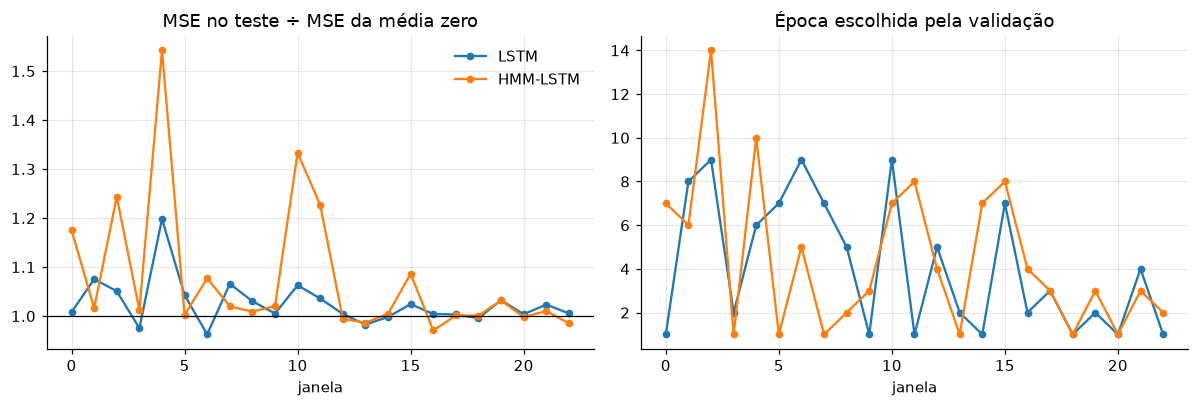

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ratio = mse.pivot(index="fold", columns="model", values="razao")
for name, label in (("lstm", "LSTM"), ("hmm_lstm", "HMM-LSTM")):
    axes[0].plot(ratio.index, ratio[name], marker="o", ms=4, label=label)
    axes[1].plot(epochs.index, epochs[name], marker="o", ms=4, label=label)
axes[0].axhline(1, color="black", lw=.8)
axes[0].set_title("MSE no teste ÷ MSE da média zero")
axes[0].set_xlabel("janela")
axes[1].set_title("Época escolhida pela validação")
axes[1].set_xlabel("janela")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_mse_relativo_e_epocas.png", bbox_inches="tight")

## Leitura

- Em 36 dos 46 ajustes (23 janelas × 2 redes) a previsão pontual da rede erra mais que
  simplesmente prever retorno zero. Nos outros, a vantagem é pequena.
- A validação escolhe épocas muito iniciais (mediana de 3; a 1ª época em 6 ou 7 das 23
  janelas). A rede não encontra no treino um padrão de retorno médio que se mantenha
  seis meses depois.
- A amostra é pequena para a rede: cerca de 700 a 840 sequências de treino por janela,
  cada uma com 42 pregões de mais de 80 variáveis. Com tão poucos exemplos, a capacidade
  extra da LSTM vira sobreajuste antes de virar sinal.
- Isso é coerente com a literatura: o sinal do retorno diário é quase imprevisível, ainda
  que sua intensidade não seja (Cont, 2001). Para o risco, a consequência é que a média
  prevista pela rede pouco ajuda e pode deslocar o VaR com ruído. O efeito disso é medido
  nos notebooks 05 e 06.